# Лабораторная работа №4. Исследование случайного леса

| Задача | Датасет | Модель |
|---|---|---|
| Классификация | GTZAN — жанр по аудиопризнакам (10 классов) | `RandomForestClassifier` |
| Регрессия | YearPredictionMSD — год выпуска песни | `RandomForestRegressor` |

Датасеты, их обоснование, разбиения train/test и метрики выбраны в ЛР1 (`lab1_knn.ipynb`, раздел 1) и не меняются. Основные метрики: **macro-F1** для классификации и **MAE** (в годах) для регрессии.

**План работы**
1. Кратко о модели.
2. Бейзлайн: случайный лес sklearn с параметрами по умолчанию.
3. Улучшение бейзлайна: гипотезы → проверка на кросс-валидации → улучшенный бейзлайн.
4. Собственная реализация случайного леса (на основе своего дерева из ЛР3): сравнение с п. 2 и п. 3.
5. Итоги и сравнение с ЛР1–ЛР3.

Импорты и общие настройки ноутбука

In [1]:
import json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import TransformedTargetRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import ExtraTreesClassifier, ExtraTreesRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, mean_absolute_error
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, cross_val_score
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from src.data import RANDOM_STATE, download_data, gtzan_split, msd_split
from src.results import RESULTS_DIR, classification_metrics, regression_metrics, save_results

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)
np.random.seed(RANDOM_STATE)

Загружаем данные с теми же фиксированными разбиениями, что и в ЛР1–ЛР3

In [2]:
download_data()
Xc_train, Xc_test, yc_train, yc_test, gc_train, gc_test = gtzan_split()
Xr_train, Xr_test, yr_train, yr_test = msd_split()
print("GTZAN train/test:", Xc_train.shape, Xc_test.shape)
print("MSD   train/test:", Xr_train.shape, Xr_test.shape)

GTZAN train/test: (7993, 57) (1997, 57)
MSD   train/test: (50000, 90) (10000, 90)


## 1. Кратко о модели

Случайный лес — ансамбль из $B$ решающих деревьев, предсказания которых усредняются: в классификации усредняются вероятности классов, в регрессии — прогнозы. Чтобы деревья различались, используются два источника случайности:
* **бэггинг** — каждое дерево обучается на бутстреп-выборке (выборка с возвращением того же размера; в неё попадает ≈63 % уникальных объектов);
* **случайные подпространства** — в каждом узле лучшее разбиение ищется только среди `max_features` случайно выбранных признаков.

Почему это работает. Если деревья имеют дисперсию $\sigma^2$ и попарную корреляцию $\rho$, то дисперсия их среднего равна $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$. Увеличение числа деревьев убирает второе слагаемое, а уменьшение `max_features` снижает корреляцию $\rho$ и тем самым первое. Смещение же у леса примерно такое же, как у одного дерева. Поэтому деревья в лесу обычно глубокие (малое смещение), а высокую дисперсию одиночного дерева, главную проблему из ЛР3, гасит усреднение.

**Out-of-bag (OOB) оценка.** Около 37 % объектов не попадают в бутстреп-выборку конкретного дерева. Прогноз для объекта по деревьям, которые его «не видели», даёт оценку качества без отдельной валидации.

Параметры по умолчанию в sklearn: 100 деревьев без ограничения глубины; `max_features="sqrt"` для классификации и `max_features=1.0` (все признаки, то есть чистый бэггинг) для регрессии.

## 2. Создание бейзлайна и оценка качества

Бейзлайн — `RandomForestClassifier` / `RandomForestRegressor` с параметрами по умолчанию на исходных признаках. Фиксируются только `random_state` для воспроизводимости и `n_jobs` для параллельного обучения деревьев; на модель они не влияют.

Бейзлайн: леса «из коробки»

In [3]:
results = {"classification": {}, "regression": {}}
RFC = lambda **kw: RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **kw)
RFR = lambda **kw: RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **kw)
t0 = time.time()
base_clf = RFC().fit(Xc_train, yc_train)
t1 = time.time()
base_reg = RFR().fit(Xr_train, yr_train)
t2 = time.time()
results["classification"]["sklearn baseline"] = classification_metrics(yc_test, base_clf.predict(Xc_test))
results["regression"]["sklearn baseline"] = regression_metrics(yr_test, base_reg.predict(Xr_test))
print(f"Время обучения: GTZAN {t1 - t0:.1f} c, MSD {t2 - t1:.1f} c")
pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T

Время обучения: GTZAN 0.6 c, MSD 53.4 c


(                  accuracy  f1_macro
 sklearn baseline      0.67    0.6678,
                     MAE    RMSE      R2
 sklearn baseline  6.902  9.5547  0.2299)

**Выводы по бейзлайну.** Случайный лес «из коробки» сразу работает хорошо — это его главное практическое достоинство.
* **Классификация:** macro-F1 намного выше, чем у одиночного дерева из ЛР3 (0.49 в бейзлайне и 0.53 в улучшенной версии), и почти на уровне улучшенных KNN и логистической регрессии (0.68) — без какой-либо предобработки и подбора параметров.
* **Регрессия:** MAE заметно лучше константы и одиночного дерева, так как усреднение 100 переобученных деревьев гасит их шум. Результат на уровне бейзлайна линейной регрессии, но уступает улучшенной линейной модели из ЛР2.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

| № | Гипотеза | Задача |
|---|---|---|
| Г1 | OOB-оценка на GTZAN будет завышена: фрагменты одного трека попадают и в бутстреп-выборку, и в OOB. Для оценки и подбора параметров нужна групповая кросс-валидация | обе |
| Г2 | Качество растёт с числом деревьев и выходит на плато (больше деревьев не вредит, но дороже) | обе |
| Г3 | Уменьшение `max_features` декоррелирует деревья и улучшит регрессию, где по умолчанию используются все признаки | обе |
| Г4 | Ограничение размера листьев (`min_samples_leaf`) уменьшит шум прогнозов в зашумлённой регрессии | обе |
| Г5 | Extra Trees (случайные пороги вместо оптимальных) ещё сильнее декоррелирует деревья | обе |
| Г6 | Признаки-проекции с учителем (LDA / PLS), которые помогли дереву в ЛР3, помогут и лесу | обе |
| Г7 | Логарифмирование таргета `log(2012 − year)` поможет и лесу | регрессия |

Гипотезы проверяются на кросс-валидации по train с теми же фолдами, что и в ЛР1–ЛР3. Тестовая выборка используется только для итоговой оценки. Проверки на MSD занимают по минуте и больше, поэтому сетка для регрессии небольшая.

Функции оценки на кросс-валидации; деревья обучаются параллельно внутри леса, поэтому фолды для MSD считаются последовательно

In [4]:
cv_c = GroupKFold(n_splits=5)
cv_r = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_clf(model):
    return cross_val_score(model, Xc_train, yc_train, cv=cv_c, groups=gc_train, scoring="f1_macro", n_jobs=1).mean()

def cv_reg(model):
    return -cross_val_score(model, Xr_train, yr_train, cv=cv_r, scoring="neg_mean_absolute_error", n_jobs=1).mean()

hyp_c = {"бейзлайн": cv_clf(RFC())}
hyp_r = {"бейзлайн": cv_reg(RFR())}
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.6866,6.7658


#### Г1. OOB-оценка против групповой кросс-валидации

OOB-прогнозы леса бейзлайна: для каждого объекта усредняются только деревья, не видевшие его при обучении

In [5]:
oob_clf = RFC(oob_score=True).fit(Xc_train, yc_train)
oob_pred_c = oob_clf.classes_[oob_clf.oob_decision_function_.argmax(axis=1)]
oob_reg = RFR(oob_score=True).fit(Xr_train, yr_train)
pd.DataFrame({
    "OOB": {"GTZAN macro-F1": f1_score(yc_train, oob_pred_c, average="macro"), "MSD MAE": mean_absolute_error(yr_train, oob_reg.oob_prediction_)},
    "кросс-валидация": {"GTZAN macro-F1": hyp_c["бейзлайн"], "MSD MAE": hyp_r["бейзлайн"]},
})

,OOB,кросс-валидация
GTZAN macro-F1,0.8629,0.6866
MSD MAE,6.8026,6.7658


**Г1 подтверждена.** На GTZAN OOB-оценка завышена примерно на 18 п.п. Бутстреп выбирает отдельные фрагменты, а не треки, поэтому для OOB-фрагмента в обучающей выборке дерева почти всегда есть 9 других фрагментов той же песни. Это та же утечка, что и при случайном разбиении в ЛР1. На MSD строки независимы (официальное разбиение UCI разводит исполнителей между train и test, а внутри train случайные фолды и бутстреп ведут себя одинаково), и OOB-оценка близка к кросс-валидации. Вывод: OOB удобно использовать для MSD, но не для GTZAN. Там гиперпараметры подбираются только по `GroupKFold`.

#### Г2. Число деревьев

GTZAN: групповая CV по числу деревьев; MSD: OOB-оценка с warm_start (лес наращивается без переобучения уже построенных деревьев). Объекты, попавшие в бутстреп-выборки всех деревьев, OOB-прогноза не имеют (sklearn ставит 0), их исключаем

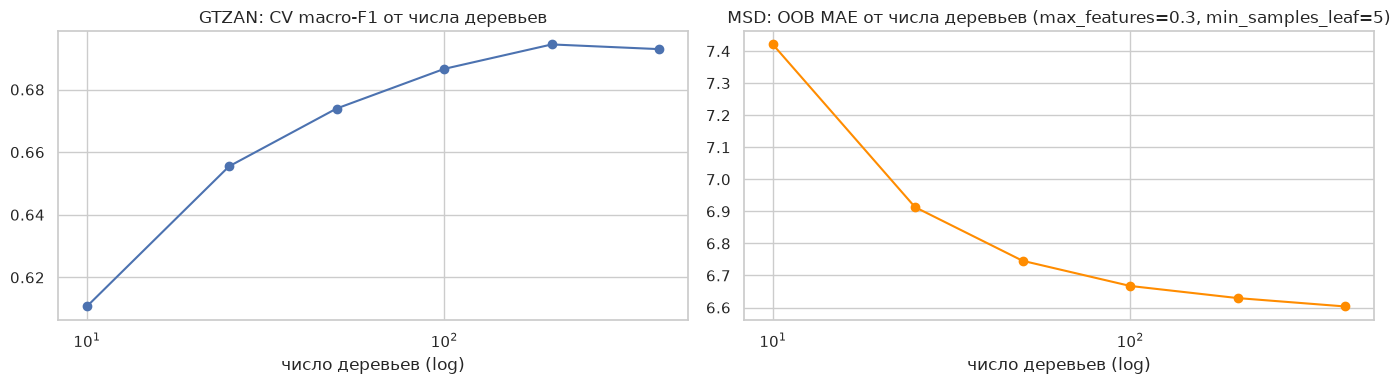

In [6]:
n_trees = [10, 25, 50, 100, 200, 400]
curve_c = {n: cv_clf(RFC(n_estimators=n)) for n in n_trees}
grow = RFR(warm_start=True, oob_score=True, max_features=0.3, min_samples_leaf=5)
curve_r = {}
for n in n_trees:
    grow.set_params(n_estimators=n).fit(Xr_train, yr_train)
    seen = grow.oob_prediction_ != 0
    curve_r[n] = mean_absolute_error(yr_train[seen], grow.oob_prediction_[seen])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(list(curve_c), list(curve_c.values()), marker="o"); axes[0].set_title("GTZAN: CV macro-F1 от числа деревьев")
axes[1].plot(list(curve_r), list(curve_r.values()), marker="o", color="darkorange"); axes[1].set_title("MSD: OOB MAE от числа деревьев (max_features=0.3, min_samples_leaf=5)")
for ax in axes: ax.set_xscale("log"); ax.set_xlabel("число деревьев (log)")
plt.tight_layout(); plt.show()
hyp_c["Г2: 400 деревьев"] = curve_c[400]

**Г2 подтверждена.** Качество быстро растёт до 100–200 деревьев и дальше выходит на плато. Каждое удвоение числа деревьев даёт всё меньший прирост, а время обучения и предсказания растёт линейно. Переобучения от числа деревьев нет: это просто усреднение. Поэтому `n_estimators` не подбирается по сетке. Для поиска остальных параметров используется 100 деревьев, а в итоговых моделях — 400, где кривые уже вышли на плато.

#### Г3. Число признаков в узле (`max_features`)

Для классификации по умолчанию sqrt(57) ≈ 7 признаков, для регрессии — все 90 признаков

In [7]:
for mf in ["log2", 0.3]:
    hyp_c[f"Г3: max_features={mf}"] = cv_clf(RFC(max_features=mf))
for mf in ["sqrt", 0.3, 0.5]:
    hyp_r[f"Г3: max_features={mf}"] = cv_reg(RFR(max_features=mf))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.6866,6.7658
Г2: 400 деревьев,0.6929,NaN
Г3: max_features=log2,0.6855,NaN
Г3: max_features=0.3,0.6807,6.7924
Г3: max_features=sqrt,NaN,6.9890
Г3: max_features=0.5,NaN,6.7524


**Г3 не подтвердилась (сама по себе).** Для регрессии с полными деревьями уменьшение `max_features` почти ничего не даёт: 50 % признаков немного лучше значения по умолчанию, 30 % — немного хуже, а `sqrt` (9 из 90 признаков) заметно хуже. Декорреляция деревьев снижает дисперсию ансамбля, но одновременно ослабляет каждое дерево: в узле может не оказаться ни одного сильного признака. Для MSD, где информативны в основном средние тембра, эти эффекты почти компенсируют друг друга. Для классификации значение по умолчанию (`sqrt`) уже близко к оптимальному. Поэтому `max_features` подбирается дальше вместе с другими параметрами, а не фиксируется.

#### Г4. Минимальный размер листа

Ограничиваем листья при max_features=0.3 для регрессии и при значении по умолчанию для классификации

In [8]:
hyp_c["Г4: min_samples_leaf=3"] = cv_clf(RFC(min_samples_leaf=3))
for leaf in [5, 10, 20]:
    hyp_r[f"Г4: max_features=0.3, min_samples_leaf={leaf}"] = cv_reg(RFR(max_features=0.3, min_samples_leaf=leaf))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.6866,6.7658
Г2: 400 деревьев,0.6929,NaN
Г3: max_features=log2,0.6855,NaN
Г3: max_features=0.3,0.6807,6.7924
Г4: min_samples_leaf=3,0.6864,NaN
Г3: max_features=sqrt,NaN,6.9890
Г3: max_features=0.5,NaN,6.7524
"Г4: max_features=0.3, min_samples_leaf=5",NaN,6.6334
"Г4: max_features=0.3, min_samples_leaf=10",NaN,6.6108
"Г4: max_features=0.3, min_samples_leaf=20",NaN,6.6153


**Г4 подтверждена для регрессии, для классификации эффекта нет.** В лесу, в отличие от одиночного дерева, оптимальные листья гораздо мельче: в ЛР3 лучшим было 200 объектов в листе, здесь — 5–20 (разница между ними мала). Усреднение по деревьям само гасит шум отдельных листьев, и сильное ограничение только увеличивает смещение. Небольшое ограничение всё же помогает: в листе из одной-двух песен прогноз — это год конкретной песни, а усреднение даже по 5–10 песням заметно устойчивее.

#### Г5. Extra Trees

ExtremelyRandomizedTrees: порог в каждом признаке выбирается случайно, а не оптимально; бутстрепа по умолчанию нет

In [9]:
hyp_c["Г5: ExtraTrees"] = cv_clf(ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1))
hyp_r["Г5: ExtraTrees (max_features=0.3, min_samples_leaf=5)"] = cv_reg(ExtraTreesRegressor(max_features=0.3, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.6866,6.7658
Г2: 400 деревьев,0.6929,NaN
Г3: max_features=log2,0.6855,NaN
Г3: max_features=0.3,0.6807,6.7924
Г4: min_samples_leaf=3,0.6864,NaN
Г5: ExtraTrees,0.6931,NaN
Г3: max_features=sqrt,NaN,6.9890
Г3: max_features=0.5,NaN,6.7524
"Г4: max_features=0.3, min_samples_leaf=5",NaN,6.6334
"Г4: max_features=0.3, min_samples_leaf=10",NaN,6.6108


**Г5: результат зависит от задачи.** На GTZAN Extra Trees немного лучше случайного леса: дополнительная случайность ещё сильнее декоррелирует деревья, а классы хорошо разделимы и «неоптимальные» пороги почти не мешают. На MSD Extra Trees хуже: связь признаков с годом слабая и зашумлённая, и случайные пороги заметно ухудшают каждое отдельное дерево. Выигрыш на GTZAN небольшой, поэтому дальше остаёмся в рамках случайного леса.

#### Г6. Признаки-проекции с учителем (LDA / PLS)

Конструкторы признаков из ЛР3: исходные признаки + 9 компонент LDA или исходные признаки + k компонент PLS (на стандартизированных признаках). Проекции обучаются только на train-части каждого фолда.

In [10]:
class PLSFeatures(BaseEstimator, TransformerMixin):
    """Компоненты PLS как признаки (PLSRegression.fit_transform возвращает пару, поэтому нужна обёртка)."""

    def __init__(self, n_components=10):
        self.n_components = n_components

    def fit(self, X, y):
        self.pls_ = PLSRegression(n_components=self.n_components, scale=False).fit(X, y)
        return self

    def transform(self, X):
        return self.pls_.transform(X)


def with_lda():
    return FeatureUnion([("orig", FunctionTransformer()), ("lda", LinearDiscriminantAnalysis())])


def with_pls(k=10):
    return FeatureUnion([("orig", FunctionTransformer()), ("pls", Pipeline([("sc", StandardScaler()), ("pls", PLSFeatures(k))]))])

Лес на исходных признаках + проекциях

In [11]:
hyp_c["Г6: + LDA"] = cv_clf(Pipeline([("feat", with_lda()), ("rf", RFC())]))
hyp_r["Г6: + PLS(10), max_features=0.3, min_samples_leaf=5"] = cv_reg(Pipeline([("feat", with_pls(10)), ("rf", RFR(max_features=0.3, min_samples_leaf=5))]))
pd.DataFrame({"GTZAN macro-F1 ↑": hyp_c, "MSD MAE ↓": hyp_r})

,GTZAN macro-F1 ↑,MSD MAE ↓
бейзлайн,0.6866,6.7658
Г2: 400 деревьев,0.6929,NaN
Г3: max_features=log2,0.6855,NaN
Г3: max_features=0.3,0.6807,6.7924
Г4: min_samples_leaf=3,0.6864,NaN
Г5: ExtraTrees,0.6931,NaN
Г6: + LDA,0.7076,NaN
Г3: max_features=sqrt,NaN,6.9890
Г3: max_features=0.5,NaN,6.7524
"Г4: max_features=0.3, min_samples_leaf=5",NaN,6.6334


**Г6 подтверждена для обеих задач.** LDA-компоненты дают лесу заметный прирост в классификации, а PLS-компоненты — в регрессии (около 0.2 года MAE), как и одиночному дереву в ЛР3. «Наклонные» разбиения по направлениям, связанным с таргетом, полезны и в ансамбле.

#### Г7. Логарифмирование таргета

Лес обучается на log(2012 - year), прогноз переводится обратно в год

In [12]:
log_y = lambda y: np.log(2012 - y)
exp_y = lambda z: 2012 - np.exp(z)
log_target = lambda model: TransformedTargetRegressor(regressor=model, func=log_y, inverse_func=exp_y)
hyp_r["Г7: log-таргет, max_features=0.3, min_samples_leaf=5"] = cv_reg(log_target(RFR(max_features=0.3, min_samples_leaf=5)))
hyp_r["Г6+Г7: + PLS(10), log-таргет"] = cv_reg(log_target(Pipeline([("feat", with_pls(10)), ("rf", RFR(max_features=0.3, min_samples_leaf=5))])))
pd.Series(hyp_r, name="MSD MAE ↓").to_frame()

,MSD MAE ↓
бейзлайн,6.7658
Г3: max_features=sqrt,6.9890
Г3: max_features=0.3,6.7924
Г3: max_features=0.5,6.7524
"Г4: max_features=0.3, min_samples_leaf=5",6.6334
"Г4: max_features=0.3, min_samples_leaf=10",6.6108
"Г4: max_features=0.3, min_samples_leaf=20",6.6153
"Г5: ExtraTrees (max_features=0.3, min_samples_leaf=5)",6.7640
"Г6: + PLS(10), max_features=0.3, min_samples_leaf=5",6.4142
"Г7: log-таргет, max_features=0.3, min_samples_leaf=5",6.3296


**Г7 подтверждена**, и в сочетании с PLS-признаками это лучший результат. Как и у дерева в ЛР3, лист усредняет $\log(2012 - y)$, и обратное преобразование даёт «геометрическое» среднее, менее чувствительное к редким старым записям. Поэтому MAE снижается.

### 3.2. Подбор гиперпараметров и улучшенный бейзлайн

Перебираем по сетке на кросс-валидации (100 деревьев):
* **классификация:** признаки (исходные / + LDA), `max_features`, `min_samples_leaf`, критерий;
* **регрессия** (PLS-признаки, логарифмирование таргета): `max_features`, `min_samples_leaf`. Сетка маленькая, потому что каждая точка — это 5 лесов по 100 деревьев на 40 000 объектов.

После подбора итоговые модели обучаются с 400 деревьями (Г2).

Сетка для классификации (GroupKFold по трекам, macro-F1)

In [13]:
grid_c = GridSearchCV(Pipeline([("feat", "passthrough"), ("rf", RFC())]), {
    "feat": ["passthrough", with_lda()],
    "rf__max_features": ["sqrt", "log2", 0.2],
    "rf__min_samples_leaf": [1, 2],
    "rf__criterion": ["gini", "entropy"],
}, cv=cv_c, scoring="f1_macro", n_jobs=1)
t0 = time.time(); grid_c.fit(Xc_train, yc_train, groups=gc_train)
print(f"{time.time() - t0:.0f} c | лучшие параметры: {grid_c.best_params_} | CV macro-F1 = {grid_c.best_score_:.4f}")
hyp_c["GridSearchCV"] = grid_c.best_score_

117 c | лучшие параметры: {'feat': FeatureUnion(transformer_list=[('orig', FunctionTransformer()),
                               ('lda', LinearDiscriminantAnalysis())]), 'rf__criterion': 'entropy', 'rf__max_features': 'log2', 'rf__min_samples_leaf': 1} | CV macro-F1 = 0.7082


Сетка для регрессии (KFold, MAE)

In [14]:
grid_r = GridSearchCV(log_target(Pipeline([("feat", with_pls(10)), ("rf", RFR())])), {
    "regressor__rf__max_features": [0.2, 0.3, 0.5],
    "regressor__rf__min_samples_leaf": [3, 5, 10],
}, cv=cv_r, scoring="neg_mean_absolute_error", n_jobs=1)
t0 = time.time(); grid_r.fit(Xr_train, yr_train)
print(f"{time.time() - t0:.0f} c | лучшие параметры: {grid_r.best_params_} | CV MAE = {-grid_r.best_score_:.4f}")
hyp_r["GridSearchCV"] = -grid_r.best_score_

634 c | лучшие параметры: {'regressor__rf__max_features': 0.5, 'regressor__rf__min_samples_leaf': 3} | CV MAE = 6.1171


Сводка проверки всех гипотез на кросс-валидации

In [15]:
pd.concat([pd.Series(hyp_c, name="GTZAN CV macro-F1 ↑"), pd.Series(hyp_r, name="MSD CV MAE ↓")], axis=1)

,GTZAN CV macro-F1 ↑,MSD CV MAE ↓
бейзлайн,0.6866,6.7658
Г2: 400 деревьев,0.6929,NaN
Г3: max_features=log2,0.6855,NaN
Г3: max_features=0.3,0.6807,6.7924
Г4: min_samples_leaf=3,0.6864,NaN
Г5: ExtraTrees,0.6931,NaN
Г6: + LDA,0.7076,NaN
GridSearchCV,0.7082,6.1171
Г3: max_features=sqrt,NaN,6.9890
Г3: max_features=0.5,NaN,6.7524


Улучшенный бейзлайн: лучшие конвейеры из GridSearchCV, переобученные на всём train с 400 деревьями

In [16]:
N_FINAL = 400
best_clf = grid_c.best_estimator_.set_params(rf__n_estimators=N_FINAL).fit(Xc_train, yc_train)
best_reg = grid_r.best_estimator_.set_params(regressor__rf__n_estimators=N_FINAL).fit(Xr_train, yr_train)
yc_pred_best, yr_pred_best = best_clf.predict(Xc_test), best_reg.predict(Xr_test)
results["classification"]["sklearn improved"] = classification_metrics(yc_test, yc_pred_best)
results["regression"]["sklearn improved"] = regression_metrics(yr_test, yr_pred_best)
pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T

(                  accuracy  f1_macro
 sklearn baseline    0.6700    0.6678
 sklearn improved    0.6965    0.6909,
                      MAE    RMSE      R2
 sklearn baseline  6.9020  9.5547  0.2299
 sklearn improved  6.2269  9.5970  0.2231)

Важность признаков в улучшенных лесах (среднее уменьшение неоднородности по всем деревьям)

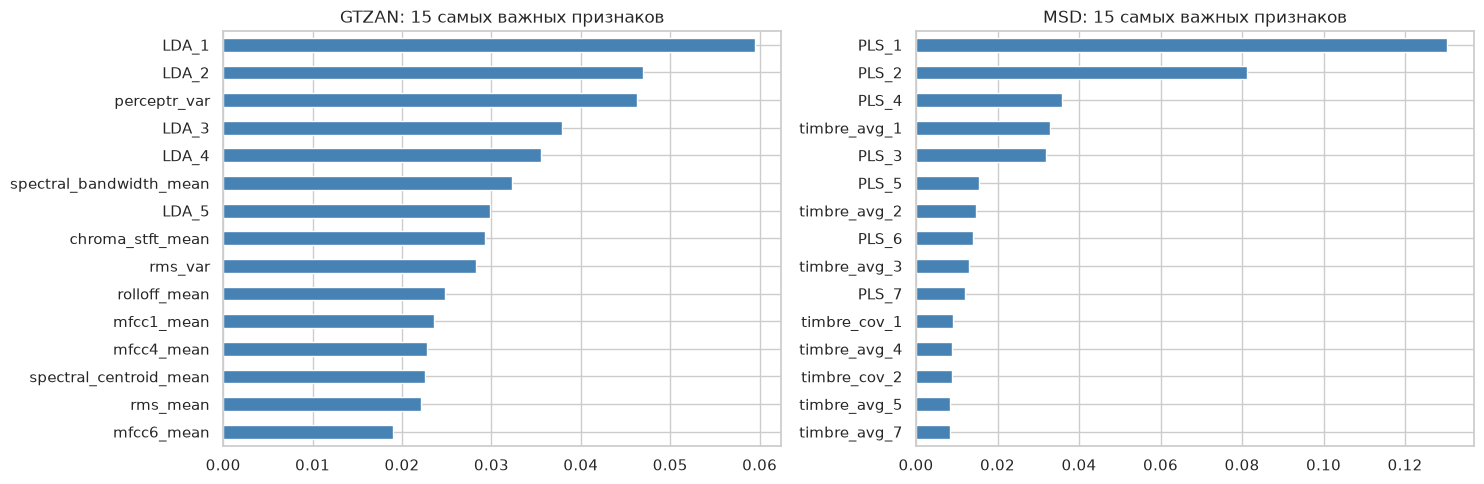

In [17]:
rf_c, rf_r = best_clf[-1], best_reg.regressor_[-1]
names_c = list(Xc_train.columns) + [f"LDA_{i + 1}" for i in range(rf_c.n_features_in_ - Xc_train.shape[1])]
names_r = list(Xr_train.columns) + [f"PLS_{i + 1}" for i in range(rf_r.n_features_in_ - Xr_train.shape[1])]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, model, names, title in [(axes[0], rf_c, names_c, "GTZAN"), (axes[1], rf_r, names_r, "MSD")]:
    pd.Series(model.feature_importances_, index=names).nlargest(15).sort_values().plot.barh(ax=ax, color="steelblue")
    ax.set_title(f"{title}: 15 самых важных признаков")
plt.tight_layout(); plt.show()

Матрица ошибок улучшенного классификатора и «прогноз vs факт» для регрессии

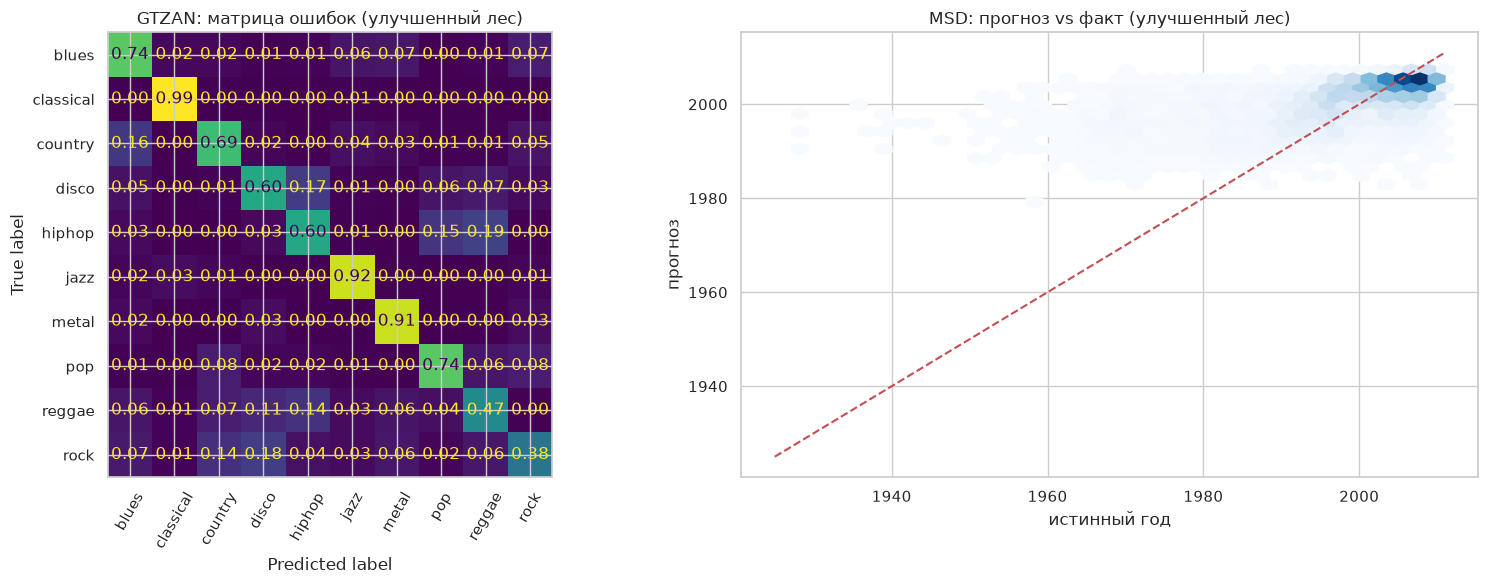

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred_best, normalize="true", values_format=".2f", ax=axes[0], colorbar=False, xticks_rotation=60)
axes[0].set_title("GTZAN: матрица ошибок (улучшенный лес)")
axes[1].hexbin(yr_test, yr_pred_best, gridsize=40, cmap="Blues", mincnt=1, extent=(1925, 2011, 1925, 2011))
axes[1].plot([1925, 2011], [1925, 2011], "r--"); axes[1].set_xlabel("истинный год"); axes[1].set_ylabel("прогноз")
axes[1].set_title("MSD: прогноз vs факт (улучшенный лес)")
plt.tight_layout(); plt.show()

**Выводы по улучшенному бейзлайну (сравнение с п. 2).**
* **Классификация:** прирост около +2 п.п. macro-F1. Его дают LDA-признаки и увеличение числа деревьев, остальные параметры по умолчанию уже близки к оптимальным. Первые две компоненты LDA — самые важные признаки. В отличие от одиночного дерева, лес активно использует и исходные признаки (`perceptr_var`, `spectral_bandwidth_mean`, `chroma_stft_mean`): из-за `max_features` в узле часто нет LDA-компонент, и важность распределяется шире.
* **Регрессия:** MAE снизился примерно на 0.7 года. Главное — PLS-признаки и логарифмирование таргета, небольшие листья тоже помогают. Подобранное `max_features=0.5` даёт лишь малый вклад. Как и в ЛР2, логарифмирование таргета снижает MAE ценой небольшого ухудшения RMSE и R². Самые важные признаки — компоненты PLS, а из исходных — средние значения тембра.

## 4. Имплементация алгоритма

### 4.1. Собственная реализация

Основа — собственное дерево CART из ЛР3 с двумя изменениями:
* **`max_features`** — в каждом узле перебираются только случайно выбранные признаки (без возвращения). Если среди них нет ни одного допустимого разбиения (например, все выбранные признаки в узле постоянны), поиск продолжается по остальным признакам, как в sklearn;
* **кодирование классов задаётся лесом** (`n_classes`): дерево, обученное на бутстреп-выборке без какого-то редкого класса, всё равно возвращает вероятности для всех классов в общем порядке.

Лес `MyRandomForest`:
1. для каждого дерева генерирует бутстреп-выборку (индексы с возвращением) и собственный `random_state`;
2. обучает деревья параллельно (`joblib.Parallel`, по процессу на ядро);
3. предсказывает усреднением: вероятностей классов (soft voting, как в sklearn) или прогнозов регрессии;
4. считает OOB-оценку: для каждого объекта усредняются прогнозы только тех деревьев, в бутстреп-выборку которых он не попал.

Отличие от sklearn: sklearn реализует бутстреп через веса объектов (сколько раз объект выбран), а моя реализация дублирует строки. Разбиения при этом одинаковые, но `min_samples_leaf` у меня считается с учётом дубликатов, а в sklearn — по уникальным объектам. Поэтому при одинаковом `min_samples_leaf` мои листья в среднем немного мельче.

Дерево из ЛР3 с поддержкой `max_features`. Изменения по сравнению с ЛР3:
* `_split_on` ищет лучшее разбиение среди заданного подмножества признаков (код поиска не изменился);
* `_best_split` берёт случайную перестановку признаков: сначала ищет среди первых `k_features_`, а если допустимого разбиения нет — среди остальных;
* `predict_value` возвращает значение в листе: вероятности всех классов или прогноз регрессии; усреднением этих значений занимается лес.

In [19]:
class MyDecisionTree:
    """CART из ЛР3 + случайный выбор признаков в узле (max_features) и заданное лесом число классов."""

    def __init__(self, criterion="gini", max_depth=None, min_samples_split=2, min_samples_leaf=1,
                 max_features=None, n_classes=None, random_state=None):
        self.criterion, self.max_depth = criterion, max_depth
        self.min_samples_split, self.min_samples_leaf = min_samples_split, min_samples_leaf
        self.max_features, self.n_classes, self.random_state = max_features, n_classes, random_state

    def _node_impurity_sum(self, stats, n):
        if self.criterion == "mse":
            s, s2 = stats
            return s2 - s ** 2 / n
        counts = stats
        if self.criterion == "gini":
            return n - (counts ** 2).sum(axis=-1) / n
        with np.errstate(divide="ignore", invalid="ignore"):
            plogp = np.where(counts > 0, counts * np.log(counts), 0.0).sum(axis=-1)
        return n * np.log(n) - plogp

    def _split_on(self, idx, feats):
        X, n, leaf = self.X_[np.ix_(idx, feats)], len(idx), self.min_samples_leaf
        order = np.argsort(X, axis=0, kind="stable")
        Xs = np.take_along_axis(X, order, axis=0)
        n_left = np.arange(1, n)[:, None]
        if self.criterion == "mse":
            ys = self.y_[idx][order]
            cs, cs2 = np.cumsum(ys, axis=0), np.cumsum(ys ** 2, axis=0)
            left, right = (cs[:-1], cs2[:-1]), (cs[-1] - cs[:-1], cs2[-1] - cs2[:-1])
        else:
            cc = np.cumsum(self.Y_[idx][order], axis=0)
            left, right = cc[:-1], cc[-1] - cc[:-1]
        cost = self._node_impurity_sum(left, n_left) + self._node_impurity_sum(right, n - n_left)
        valid = (Xs[1:] > Xs[:-1].astype(np.float64) + 1e-7) & (n_left >= leaf) & (n - n_left >= leaf)
        if not valid.any():
            return None
        cost = np.where(valid, cost, np.inf)
        pos, j = np.unravel_index(np.argmin(cost), cost.shape)
        lo, hi = float(Xs[pos, j]), float(Xs[pos + 1, j])
        thr = lo / 2.0 + hi / 2.0
        if thr == hi or not np.isfinite(thr):
            thr = lo
        return feats[j], float(thr), cost[pos, j], order[: pos + 1, j], order[pos + 1:, j]

    def _best_split(self, idx):
        perm = self.rng_.permutation(self.n_features_)
        split = self._split_on(idx, np.sort(perm[: self.k_features_]))
        if split is None and self.k_features_ < self.n_features_:
            split = self._split_on(idx, np.sort(perm[self.k_features_:]))
        return split

    def fit(self, X, y):
        self.X_ = np.asarray(X, dtype=np.float32)
        self.n_features_ = self.X_.shape[1]
        mf = self.max_features
        self.k_features_ = (self.n_features_ if mf is None else max(1, int(np.sqrt(self.n_features_))) if mf == "sqrt"
                            else max(1, int(np.log2(self.n_features_))) if mf == "log2" else max(1, int(mf * self.n_features_)))
        self.rng_ = np.random.default_rng(self.random_state)
        if self.criterion == "mse":
            self.y_ = np.asarray(y, dtype=np.float64)
        elif self.n_classes is not None:
            self.classes_ = np.arange(self.n_classes)
            self.Y_ = np.eye(self.n_classes)[np.asarray(y)]
        else:
            self.classes_, codes = np.unique(y, return_inverse=True)
            self.Y_ = np.eye(len(self.classes_))[codes]
        self.feature, self.threshold, self.left, self.right, self.value = [], [], [], [], []
        self.feature_importances_ = np.zeros(self.n_features_)
        stack = [(np.arange(len(self.X_)), 0, None, None)]
        while stack:
            idx, depth, parent, is_left = stack.pop()
            node = len(self.feature)
            self.feature.append(-1); self.threshold.append(0.0); self.left.append(-1); self.right.append(-1)
            if self.criterion == "mse":
                self.value.append(np.array([self.y_[idx].mean()]))
                impurity_sum = len(idx) * self.y_[idx].var()
            else:
                counts = self.Y_[idx].sum(axis=0)
                self.value.append(counts / len(idx))
                impurity_sum = self._node_impurity_sum(counts, len(idx))
            if parent is not None:
                (self.left if is_left else self.right)[parent] = node
            if ((self.max_depth is not None and depth >= self.max_depth) or len(idx) < self.min_samples_split
                    or len(idx) < 2 * self.min_samples_leaf or impurity_sum <= 1e-12):
                continue
            split = self._best_split(idx)
            if split is None:
                continue
            feat, thr, cost, li, ri = split
            self.feature[node], self.threshold[node] = int(feat), thr
            self.feature_importances_[feat] += impurity_sum - cost
            stack.append((idx[ri], depth + 1, node, False))
            stack.append((idx[li], depth + 1, node, True))
        self.feature, self.threshold = np.array(self.feature), np.array(self.threshold)
        self.left, self.right, self.value = np.array(self.left), np.array(self.right), np.array(self.value)
        self.feature_importances_ /= max(self.feature_importances_.sum(), 1e-12)
        del self.X_, self.rng_
        return self

    def apply(self, X):
        X = np.asarray(X, dtype=np.float32)
        node = np.zeros(len(X), dtype=np.int64)
        active = self.feature[node] >= 0
        while active.any():
            a = np.where(active)[0]
            go_left = X[a, self.feature[node[a]]] <= self.threshold[node[a]]
            node[a] = np.where(go_left, self.left[node[a]], self.right[node[a]])
            active[a] = self.feature[node[a]] >= 0
        return node

    def predict_value(self, X):
        return self.value[self.apply(X)]

Лес `MyRandomForest`. Функция `_fit_one_tree` выполняется в отдельном процессе: строит бутстреп-выборку, обучает на ней дерево и возвращает его вместе с индексами OOB-объектов. Для каждого дерева генерируется собственный seed из общего `random_state`, поэтому результат воспроизводим и не зависит от числа процессов. OOB-прогноз (`oob_prediction_`) — среднее значение по деревьям, не видевшим объект; объекты, попавшие во все бутстреп-выборки (при 100 деревьях их практически нет), остаются `NaN`.

In [20]:
def _fit_one_tree(tree_params, X, y, seed, bootstrap):
    rng = np.random.default_rng(seed)
    n = len(X)
    idx = rng.integers(0, n, n) if bootstrap else np.arange(n)
    tree = MyDecisionTree(**tree_params, random_state=seed).fit(X[idx], y[idx])
    oob = np.setdiff1d(np.arange(n), idx)
    return tree, oob


class MyRandomForest:
    """Случайный лес: бутстреп + случайные подпространства признаков, усреднение деревьев, OOB-оценка."""

    def __init__(self, task="classification", n_estimators=100, criterion=None, max_features="sqrt",
                 max_depth=None, min_samples_leaf=1, bootstrap=True, oob_score=False, n_jobs=-1, random_state=None):
        self.task, self.n_estimators, self.criterion, self.max_features = task, n_estimators, criterion, max_features
        self.max_depth, self.min_samples_leaf, self.bootstrap = max_depth, min_samples_leaf, bootstrap
        self.oob_score, self.n_jobs, self.random_state = oob_score, n_jobs, random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        if self.task == "classification":
            self.classes_, y = np.unique(y, return_inverse=True)
            criterion, n_classes = self.criterion or "gini", len(self.classes_)
        else:
            y = np.asarray(y, dtype=np.float64)
            criterion, n_classes = "mse", None
        params = dict(criterion=criterion, max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf,
                      max_features=self.max_features, n_classes=n_classes)
        seeds = np.random.default_rng(self.random_state).integers(0, 2 ** 31, self.n_estimators)
        fitted = Parallel(n_jobs=self.n_jobs)(delayed(_fit_one_tree)(params, X, y, s, self.bootstrap) for s in seeds)
        self.estimators_ = [t for t, _ in fitted]
        self.feature_importances_ = np.mean([t.feature_importances_ for t in self.estimators_], axis=0)
        if self.oob_score:
            width = n_classes if n_classes else 1
            acc, cnt = np.zeros((len(X), width)), np.zeros(len(X))
            for tree, oob in fitted:
                acc[oob] += tree.predict_value(X[oob]); cnt[oob] += 1
            seen = cnt > 0
            self.oob_prediction_ = np.full((len(X), width), np.nan)
            self.oob_prediction_[seen] = acc[seen] / cnt[seen, None]
        return self

    def _mean_value(self, X):
        X = np.asarray(X, dtype=np.float32)
        return np.mean([t.predict_value(X) for t in self.estimators_], axis=0)

    def predict_proba(self, X):
        return self._mean_value(X)

    def predict(self, X):
        v = self._mean_value(X)
        return self.classes_[v.argmax(axis=1)] if self.task == "classification" else v[:, 0]

Проверка корректности: сравниваем с sklearn при одинаковых параметрах. Деревья случайны, поэтому сравниваются метрики, а не отдельные прогнозы; для масштаба приведён разброс sklearn по разным random_state

In [21]:
rows = []
for name, X_tr, y_tr, X_te, y_te, task, kw in [
        ("GTZAN, sqrt", Xc_train, yc_train, Xc_test, yc_test, "classification", dict(max_features="sqrt")),
        ("MSD, 0.3 / leaf 5", Xr_train, yr_train, Xr_test, yr_test, "regression", dict(max_features=0.3, min_samples_leaf=5))]:
    Sk = RandomForestClassifier if task == "classification" else RandomForestRegressor
    metric = (lambda y, p: f1_score(y, p, average="macro")) if task == "classification" else mean_absolute_error
    sk_scores = [metric(y_te, Sk(n_estimators=100, random_state=s, n_jobs=-1, **kw).fit(X_tr, y_tr).predict(X_te)) for s in range(3)]
    t0 = time.time()
    my = MyRandomForest(task, n_estimators=100, random_state=RANDOM_STATE, **kw).fit(X_tr, y_tr)
    rows.append({"тест": name, "метрика": "macro-F1" if task == "classification" else "MAE",
                 "sklearn (3 seed)": " / ".join(f"{s:.4f}" for s in sk_scores), "моя реализация": metric(y_te, my.predict(X_te)),
                 "время моей, c": time.time() - t0})
pd.DataFrame(rows)

,тест,метрика,sklearn (3 seed),моя реализация,"время моей, c"
0,"GTZAN, sqrt",macro-F1,0.6896 / 0.6847 / 0.6706,0.6685,5.4268
1,"MSD, 0.3 / leaf 5",MAE,6.7658 / 6.7718 / 6.7686,6.7928,48.1219


Метрики собственного леса близки к sklearn. Для случайного алгоритма это и есть критерий корректности: совпадения отдельных прогнозов ждать нельзя, ведь бутстреп-выборки и подмножества признаков генерируются разными генераторами случайных чисел. В классификации разброс sklearn по `random_state` составляет около 2 п.п. (лес sklearn в бейзлайне с `random_state=42` дал 0.668), и собственный лес укладывается в него. В регрессии собственный лес на ~0.02 года хуже лесов sklearn. Это объясняется разницей в `min_samples_leaf`, описанной выше: с дубликатами строк мои листья в среднем мельче, и прогнозы немного шумнее.

### 4.2. Собственная реализация в условиях бейзлайна (сравнение с п. 2)

Те же условия, что в п. 2: 100 деревьев без ограничений, max_features по умолчанию sklearn (sqrt для классификации, все признаки для регрессии)

In [22]:
t0 = time.time()
my_base_clf = MyRandomForest("classification", n_estimators=100, max_features="sqrt", random_state=RANDOM_STATE).fit(Xc_train, yc_train)
results["classification"]["custom baseline"] = classification_metrics(yc_test, my_base_clf.predict(Xc_test))
t1 = time.time()
my_base_reg = MyRandomForest("regression", n_estimators=100, max_features=None, random_state=RANDOM_STATE).fit(Xr_train, yr_train)
results["regression"]["custom baseline"] = regression_metrics(yr_test, my_base_reg.predict(Xr_test))
print(f"Время: классификация {t1 - t0:.0f} c, регрессия {time.time() - t1:.0f} c")
cmp = ["sklearn baseline", "custom baseline"]
pd.DataFrame(results["classification"]).T.loc[cmp], pd.DataFrame(results["regression"]).T.loc[cmp]

Время: классификация 5 c, регрессия 161 c


(                  accuracy  f1_macro
 sklearn baseline    0.6700    0.6678
 custom baseline     0.6705    0.6685,
                      MAE    RMSE      R2
 sklearn baseline  6.9020  9.5547  0.2299
 custom baseline   6.8927  9.5502  0.2306)

**Выводы.** В условиях бейзлайна собственный лес даёт то же качество, что и sklearn: отличия в пределах случайного разброса. При `min_samples_leaf=1` разницы в подсчёте листьев нет. Обучение медленнее: для регрессии с полными деревьями на всех 90 признаках примерно в 3 раза (≈160 с против ≈50 с у sklearn). Это ожидаемо: дерево на Python и NumPy против оптимизированного Cython-кода sklearn.

### 4.3. Собственная реализация с техниками улучшенного бейзлайна (сравнение с п. 3)

Используем те же признаки (исходные + LDA / PLS, преобразования обучены sklearn на train), логарифмирование таргета, гиперпараметры из п. 3.2 и 400 деревьев.

Признаки — все шаги лучшего конвейера, кроме леса; гиперпараметры — из GridSearchCV

In [23]:
pc = {k.split("__")[-1]: v for k, v in grid_c.best_params_.items() if k.startswith("rf__")}
pr = {k.split("__")[-1]: v for k, v in grid_r.best_params_.items() if "__rf__" in k}
Fc_train, Fc_test = best_clf[:-1].transform(Xc_train), best_clf[:-1].transform(Xc_test)
Fr_train, Fr_test = best_reg.regressor_[:-1].transform(Xr_train), best_reg.regressor_[:-1].transform(Xr_test)

t0 = time.time()
my_clf = MyRandomForest("classification", n_estimators=N_FINAL, random_state=RANDOM_STATE, **pc).fit(Fc_train, yc_train)
results["classification"]["custom improved"] = classification_metrics(yc_test, my_clf.predict(Fc_test))
t1 = time.time()
my_reg = MyRandomForest("regression", n_estimators=N_FINAL, random_state=RANDOM_STATE, oob_score=True, **pr).fit(Fr_train, log_y(yr_train))
results["regression"]["custom improved"] = regression_metrics(yr_test, exp_y(my_reg.predict(Fr_test)))
print(f"Время: классификация {t1 - t0:.0f} c, регрессия {time.time() - t1:.0f} c | параметры: {pc}, {pr}")
print(f"OOB MAE собственного леса на train: {mean_absolute_error(yr_train, exp_y(my_reg.oob_prediction_[:, 0])):.4f}")
cmp = ["sklearn improved", "custom improved"]
pd.DataFrame(results["classification"]).T.loc[cmp], pd.DataFrame(results["regression"]).T.loc[cmp]

Время: классификация 25 c, регрессия 354 c | параметры: {'criterion': 'entropy', 'max_features': 'log2', 'min_samples_leaf': 1}, {'max_features': 0.5, 'min_samples_leaf': 3}
OOB MAE собственного леса на train: 6.0907


(                  accuracy  f1_macro
 sklearn improved    0.6965    0.6909
 custom improved     0.6945    0.6888,
                      MAE    RMSE      R2
 sklearn improved  6.2269  9.5970  0.2231
 custom improved   6.2266  9.5978  0.2229)

**Выводы.** С техниками улучшенного бейзлайна собственный лес снова повторяет качество sklearn в пределах случайного разброса. OOB-оценка собственного леса на MSD близка к ошибке на кросс-валидации и на тесте, то есть и она реализована корректно. Как и в предыдущих ЛР, итоговое качество определяется постановкой (признаки, `max_features`, размер листьев, преобразование таргета), а не реализацией.

## 5. Итоги

Итоговые таблицы и сохранение результатов ЛР4

In [24]:
res_c, res_r = pd.DataFrame(results["classification"]).T, pd.DataFrame(results["regression"]).T
path = save_results("lab4_forest", results)
print("Результаты сохранены в", path.relative_to(ROOT))
display(res_c.style.highlight_max(color="lightgreen").format("{:.4f}"))
display(res_r.style.highlight_min(subset=["MAE", "RMSE"], color="lightgreen").highlight_max(subset=["R2"], color="lightgreen").format("{:.4f}"))

Результаты сохранены в results/lab4_forest.json


,accuracy,f1_macro
sklearn baseline,0.6700,0.6678
sklearn improved,0.6965,0.6909
custom baseline,0.6705,0.6685
custom improved,0.6945,0.6888


,MAE,RMSE,R2
sklearn baseline,6.9020,9.5547,0.2299
sklearn improved,6.2269,9.5970,0.2231
custom baseline,6.8927,9.5502,0.2306
custom improved,6.2266,9.5978,0.2229


Сравнение улучшенных моделей ЛР1–ЛР4 на тесте

In [25]:
labs = {"KNN (ЛР1)": "lab1_knn", "Линейные модели (ЛР2)": "lab2_linear", "Решающее дерево (ЛР3)": "lab3_tree"}
rows = {name: json.loads((RESULTS_DIR / f"{f}.json").read_text()) for name, f in labs.items()}
rows["Случайный лес (ЛР4)"] = results
pd.DataFrame({name: {"GTZAN macro-F1 ↑": r["classification"]["sklearn improved"]["f1_macro"],
                     "MSD MAE ↓": r["regression"]["sklearn improved"]["MAE"],
                     "MSD R² ↑": r["regression"]["sklearn improved"]["R2"]} for name, r in rows.items()}).T

,GTZAN macro-F1 ↑,MSD MAE ↓,MSD R² ↑
KNN (ЛР1),0.6828,7.0208,0.1805
Линейные модели (ЛР2),0.6763,6.3337,0.2064
Решающее дерево (ЛР3),0.5314,6.4885,0.1807
Случайный лес (ЛР4),0.6909,6.2269,0.2231


### Выводы по лабораторной работе

1. **Бейзлайн.** Случайный лес «из коробки» — самый сильный бейзлайн в классификации: без предобработки и подбора параметров он почти выходит на уровень улучшенных KNN и линейных моделей. В регрессии он на уровне бейзлайна линейной регрессии и заметно превосходит одиночное дерево. Усреднение многих переобученных деревьев гасит их дисперсию, главный недостаток дерева из ЛР3.
2. **Улучшение бейзлайна.**
   * На GTZAN OOB-оценка завышена из-за фрагментов одного трека, поэтому параметры подбираются только по групповой кросс-валидации.
   * Число деревьев не переобучает модель, а выходит на плато.
   * `max_features` сам по себе почти не влияет: декорреляция деревьев компенсируется их ослаблением. Для регрессии помогают небольшие листья (5–20 объектов, а не 200, как у одиночного дерева). Для классификации параметры по умолчанию почти оптимальны.
   * Проекции с учителем (LDA / PLS) и логарифмирование таргета, найденные в ЛР2–ЛР3, работают и для леса.
3. **Собственная реализация** (дерево из ЛР3 + случайные подпространства признаков, бутстреп, параллельное обучение, OOB) даёт то же качество, что и sklearn: в бейзлайне и улучшенной версии отличия в третьем знаке.
4. **Сравнение с ЛР1–ЛР3.** Случайный лес — лучшая модель на текущий момент в обеих задачах: в регрессии он обгоняет и линейную модель со сплайнами. Его ограничение в том, что деревья строятся независимо и каждое пытается решить задачу целиком. Градиентный бустинг (ЛР5) строит деревья последовательно, каждое исправляет ошибки предыдущих. Это позволяет уменьшать не только дисперсию, но и смещение.